## TriKinetics DAM (Drosophila Activity Monitor) Data Pipeline from 9/18 and 9/22

In [1]:
import csv, re, collections, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# ============================ SETTINGS ============================
FILENAME          = 'DAM Monitor 1 Sept 18-22.txt'
DATA_TYPE         = 'MT'      # MT = moves total (CT = counts total)
BIN               = '30min'   # bin size for plots
SLEEP_MIN         = 5         # minutes with zero movement = sleep
TRIM_START_MIN    = 60        # skip the first N minutes after loading (handling/acclimation), e.g. 60
POOL_CONTROLS     = True      # merged Control1 + Control2 into one "Control" group
AUTO_EXCLUDE_ZERO = True      # drop tubes with exactly zero movement for the whole run

In [3]:
# One entry per 24 h run.
WINDOWS = {
 'W1': dict(start='2026-09-19 12:50', end='2026-09-20 12:50', exclude={},
   labels=["IGMedOrRM","TGLoYWF","TGHiOrRM","Control1YWM","IGMedYWF","IGHiOrRM","Control1OrRF","TGMedYWM",
           "TGLoOrRM","IGHiYWM","Control1YWF","TGMedOrRF","TGHiYWF","Control2YWF","IGLoOrRM","IGHiOrRF",
           "Control1OrRM","IGLoYWF","IGMedOrRF","TGHiOrRF","IGLoYWM","Control2OrRM","TGMedYWF","IGLoOrRF",
           "IGHiYWF","TGMedOrRM","TGLoYWM","IGMedYWM","TGLoOrRF","Control2OrRF","Control2YWM","TGHiYWM"]),
 'W2': dict(start='2026-09-20 13:06', end='2026-09-21 13:06', exclude={},
   labels=["IGLoOrRF","TGLoYWM","TGHiYWM","Control1OrRM","Control1YWM","TGMedOrRM","IGMedYWF","Control1OrRF",
           "TGHiOrRF","IGMedOrRM","Control2OrRF","IGLoYWM","IGHiOrRF","TGHiYWF","Control1YWF","IGHiYWF",
           "TGLoYWF","Control2YWM","TGMedOrRF","TGMedYWM","IGLoYWF","IGMedYWM","IGHiYWM","IGHiOrRM",
           "Control2OrRM","TGLoOrRF","TGMedYWF","IGLoOrRM","IGMedOrRF","TGHiOrRM","TGLoOrRM","Control2YWF"]),
 'W3': dict(start='2026-09-21 13:19', end='2026-09-22 13:19',
   exclude={8: 'dead', 19: 'stuck to food but alive'},
   labels=["IGLoOrRF","IGMedYWF","TGMedYWF","IGMedOrRM","IGHiYWF","IGLoYWF","Control1YWM","TGHiOrRM",
           "IGMedYWM","TGHiYWM","TGHiYWF","TGHiOrRF","Control1OrRF","Control1YWF","Control2OrRF","TGLoOrRM",
           "IGMedOrRF","IGHiOrRM","TGMedOrRF","Control2YWM","IGLoYWM","TGLoYWM","IGHiYWM","Control1OrRM",
           "TGMedYWM","IGLoOrRM","TGLoYWF","Control2OrRM","IGHiOrRF","TGMedOrRM","Control2YWF","TGLoOrRF"]),
}

In [4]:
TUBES = [f'tube_{i}' for i in range(1, 33)]
COLS = ['index','date','time','status','extra','monitor','tube_row',
        'dtype','unused','light'] + TUBES            # 10 info columns + 32 tubes

In [5]:
raw = pd.read_csv(FILENAME, sep='\t', header=None, names=COLS, quoting=csv.QUOTE_NONE)
raw['datetime'] = pd.to_datetime(raw['date'] + ' ' + raw['time'], format='%d %b %y %H:%M:%S').dt.floor('min')
print('Rows per data type in the file:'); print(raw['dtype'].value_counts().to_string())

Rows per data type in the file:
dtype
MT     5945
CT     5945
D12    5945
D34    5945
L12    5945
L34    5945
Rt     5945
Pn     5945
Ct       38


In [6]:
d = raw[raw['dtype'] == DATA_TYPE].sort_values('datetime', kind='stable')
d = d.drop_duplicates('datetime').set_index('datetime')
moves = d[TUBES].apply(pd.to_numeric, errors='coerce')
moves = moves.mask(moves == 65535)                       # 65535 = invalid marker
full = pd.date_range(moves.index.min(), moves.index.max(), freq='1min')
moves = moves.reindex(full)                              # missing minutes stay NaN (gaps)
moves.columns = range(1, 33)                             # tube numbers 1..32
light_min = d['light'].reindex(full).ffill()             # 1 = lights on, 0 = off
print(f'{DATA_TYPE}: {moves.index.min()} -> {moves.index.max()}')

MT: 2026-09-18 12:43:00 -> 2026-09-22 16:11:00


In [7]:
gaps = moves.isna().all(axis=1)
g = (gaps != gaps.shift()).cumsum()
print('Logging gaps (monitor paused, e.g. while tubes were swapped):')
for _, s in gaps.groupby(g):
    if s.iloc[0]: print(f'  {s.index[0]} -> {s.index[-1]}  ({len(s)} min)')

print('\nLight changes (1 = on, 0 = off):')
print(light_min[light_min.diff().fillna(0) != 0].to_string())

Logging gaps (monitor paused, e.g. while tubes were swapped):
  2026-09-20 12:54:00 -> 2026-09-20 13:06:00  (13 min)
  2026-09-21 13:08:00 -> 2026-09-21 13:18:00  (11 min)

Light changes (1 = on, 0 = off):
2026-09-19 12:51:00    1.0
2026-09-19 21:09:00    0.0
2026-09-20 09:11:00    1.0
2026-09-21 18:07:00    0.0
2026-09-21 18:08:00    1.0
2026-09-21 20:55:00    0.0
2026-09-22 08:58:00    1.0


In [8]:
ALL_TRT = ['Control1','Control2','TGHi','TGMed','TGLo','IGHi','IGMed','IGLo']
CANON   = {t.lower(): t for t in ALL_TRT}
PAT = re.compile(r'^(Control1|Control2|TGHi|TGMed|TGLo|IGHi|IGMed|IGLo)(OrR|YW)([MF])$', re.I)
EXPECTED = [f'{t}{s}{x}' for t in ALL_TRT for s in ('OrR','YW') for x in 'MF']   # 32 unique groups

In [9]:
def parse(lab):
    m = PAT.match(lab.strip())
    assert m, f'Label not recognised: {lab!r}'
    trt, strain, sex = m.groups()
    return CANON[trt.lower()], ('OrR' if strain.lower() == 'orr' else 'YW'), sex.upper()

In [10]:
layout = {}
for name, w in WINDOWS.items():
    labs = w['labels']
    assert len(labs) == 32, f'{name}: need 32 labels, got {len(labs)}'
    lay = pd.DataFrame([parse(l) for l in labs], columns=['treatment','strain','sex'], index=range(1, 33))
    lay['label'] = [l.strip() for l in labs]
    lay['trt_plot'] = lay['treatment'].str.replace(r'^Control\d$', 'Control', regex=True) if POOL_CONTROLS else lay['treatment']
    layout[name] = lay

    # ---- label check: every group should appear exactly once per run ----
    cnt = collections.Counter(lay['label'])
    dupes   = {k: [t for t in lay.index if lay.loc[t, 'label'] == k] for k, n in cnt.items() if n > 1}
    missing = [e for e in EXPECTED if e not in cnt]
    if dupes or missing:
        print(f'WARNING {name}: labels used twice (label: tubes) = {dupes}')
        print(f'           labels never used = {missing}')
        print('           -> probably a typo in one of the duplicated tubes. Fix it in WINDOWS above.\n')
    else:
        print(f'{name}: labels OK (32 unique groups)')

W1: labels OK (32 unique groups)
W2: labels OK (32 unique groups)
W3: labels OK (32 unique groups)


In [11]:
ORDER = (['Control'] + ALL_TRT[2:]) if POOL_CONTROLS else ALL_TRT
COLORS = {t: plt.cm.tab10(i) for i, t in enumerate(ORDER)}

def sleep_mask(col):
    z = (col == 0)
    gr = (z != z.shift()).cumsum()
    return z & (z.groupby(gr).transform('size') >= SLEEP_MIN)

In [12]:
mv, binned_all, rows = {}, {}, []
for name, w in WINDOWS.items():
    start = pd.Timestamp(w['start']) + pd.Timedelta(minutes=TRIM_START_MIN)
    m = moves.loc[start:pd.Timestamp(w['end'])].copy()
    mv[name] = m
    binned_all[name] = m.resample(BIN).sum(min_count=1)

    sleep = m.apply(sleep_mask).astype(float).where(m.notna())
    tot, last6 = m.sum(), m.iloc[-360:].sum()
    med = tot.median()
    for tube in range(1, 33):
        reasons, notes = [], []
        if tube in w['exclude']:                       reasons.append(w['exclude'][tube])
        if AUTO_EXCLUDE_ZERO and tot[tube] == 0:       reasons.append('no movement at all')
        if tot[tube] > 0 and last6[tube] == 0:         notes.append('no movement last 6h')
        if 0 < tot[tube] < 0.25 * med:                 notes.append('very low total')
        rows.append(dict(window=name, tube=tube, **layout[name].loc[tube].to_dict(),
                         total_moves=tot[tube], mean_per_min=m[tube].mean(),
                         sleep_min_per_h=sleep[tube].mean() * 60,
                         excluded=bool(reasons), reason='; '.join(reasons), notes='; '.join(notes)))

In [13]:
summary = pd.DataFrame(rows)
ok = summary[~summary['excluded']]
print(f'{len(summary)} tubes total, {summary["excluded"].sum()} excluded, {len(ok)} used for group stats')
print('\nExcluded or flagged tubes: CHECK THESE BY EYE')
display(summary[summary['excluded'] | (summary['notes'] != '')]
        [['window','tube','label','total_moves','excluded','reason','notes']].round(0))

96 tubes total, 5 excluded, 91 used for group stats

Excluded or flagged tubes: CHECK THESE BY EYE


,window,tube,label,total_moves,excluded,reason,notes
2,W1,3,TGHiOrRM,0.0,True,no movement at all,
3,W1,4,Control1YWM,0.0,True,no movement at all,
5,W1,6,IGHiOrRM,0.0,True,no movement at all,
19,W1,20,TGHiOrRF,1802.0,False,,no movement last 6h
29,W1,30,Control2OrRF,1251.0,False,,very low total
31,W1,32,TGHiYWM,1163.0,False,,no movement last 6h; very low total
71,W3,8,TGHiOrRM,9466.0,True,dead,
76,W3,13,Control1OrRF,1779.0,False,,very low total
82,W3,19,TGMedOrRF,8059.0,True,stuck to food but alive,


In [14]:
def shade_dark(ax):
    dark = (light_min == 0)
    gr = (dark != dark.shift()).cumsum()
    for _, s in dark.groupby(gr):
        if s.iloc[0]:
            ax.axvspan(s.index[0], s.index[-1], color='0.85', zorder=0)

def flagged(name, tube):
    r = summary[(summary.window == name) & (summary.tube == tube)].iloc[0]
    return r['excluded'] or r['notes'] != ''

def get_window(name):
    b, lay = binned_all[name], layout[name]
    used = [t for t in range(1, 33)
            if not summary[(summary.window == name) & (summary.tube == t)].iloc[0]['excluded']]
    return b, lay, used

#### Figure A: 32 mini plots, one per tube.
2026-09-19 12:50 to 2026-09-20 12:50

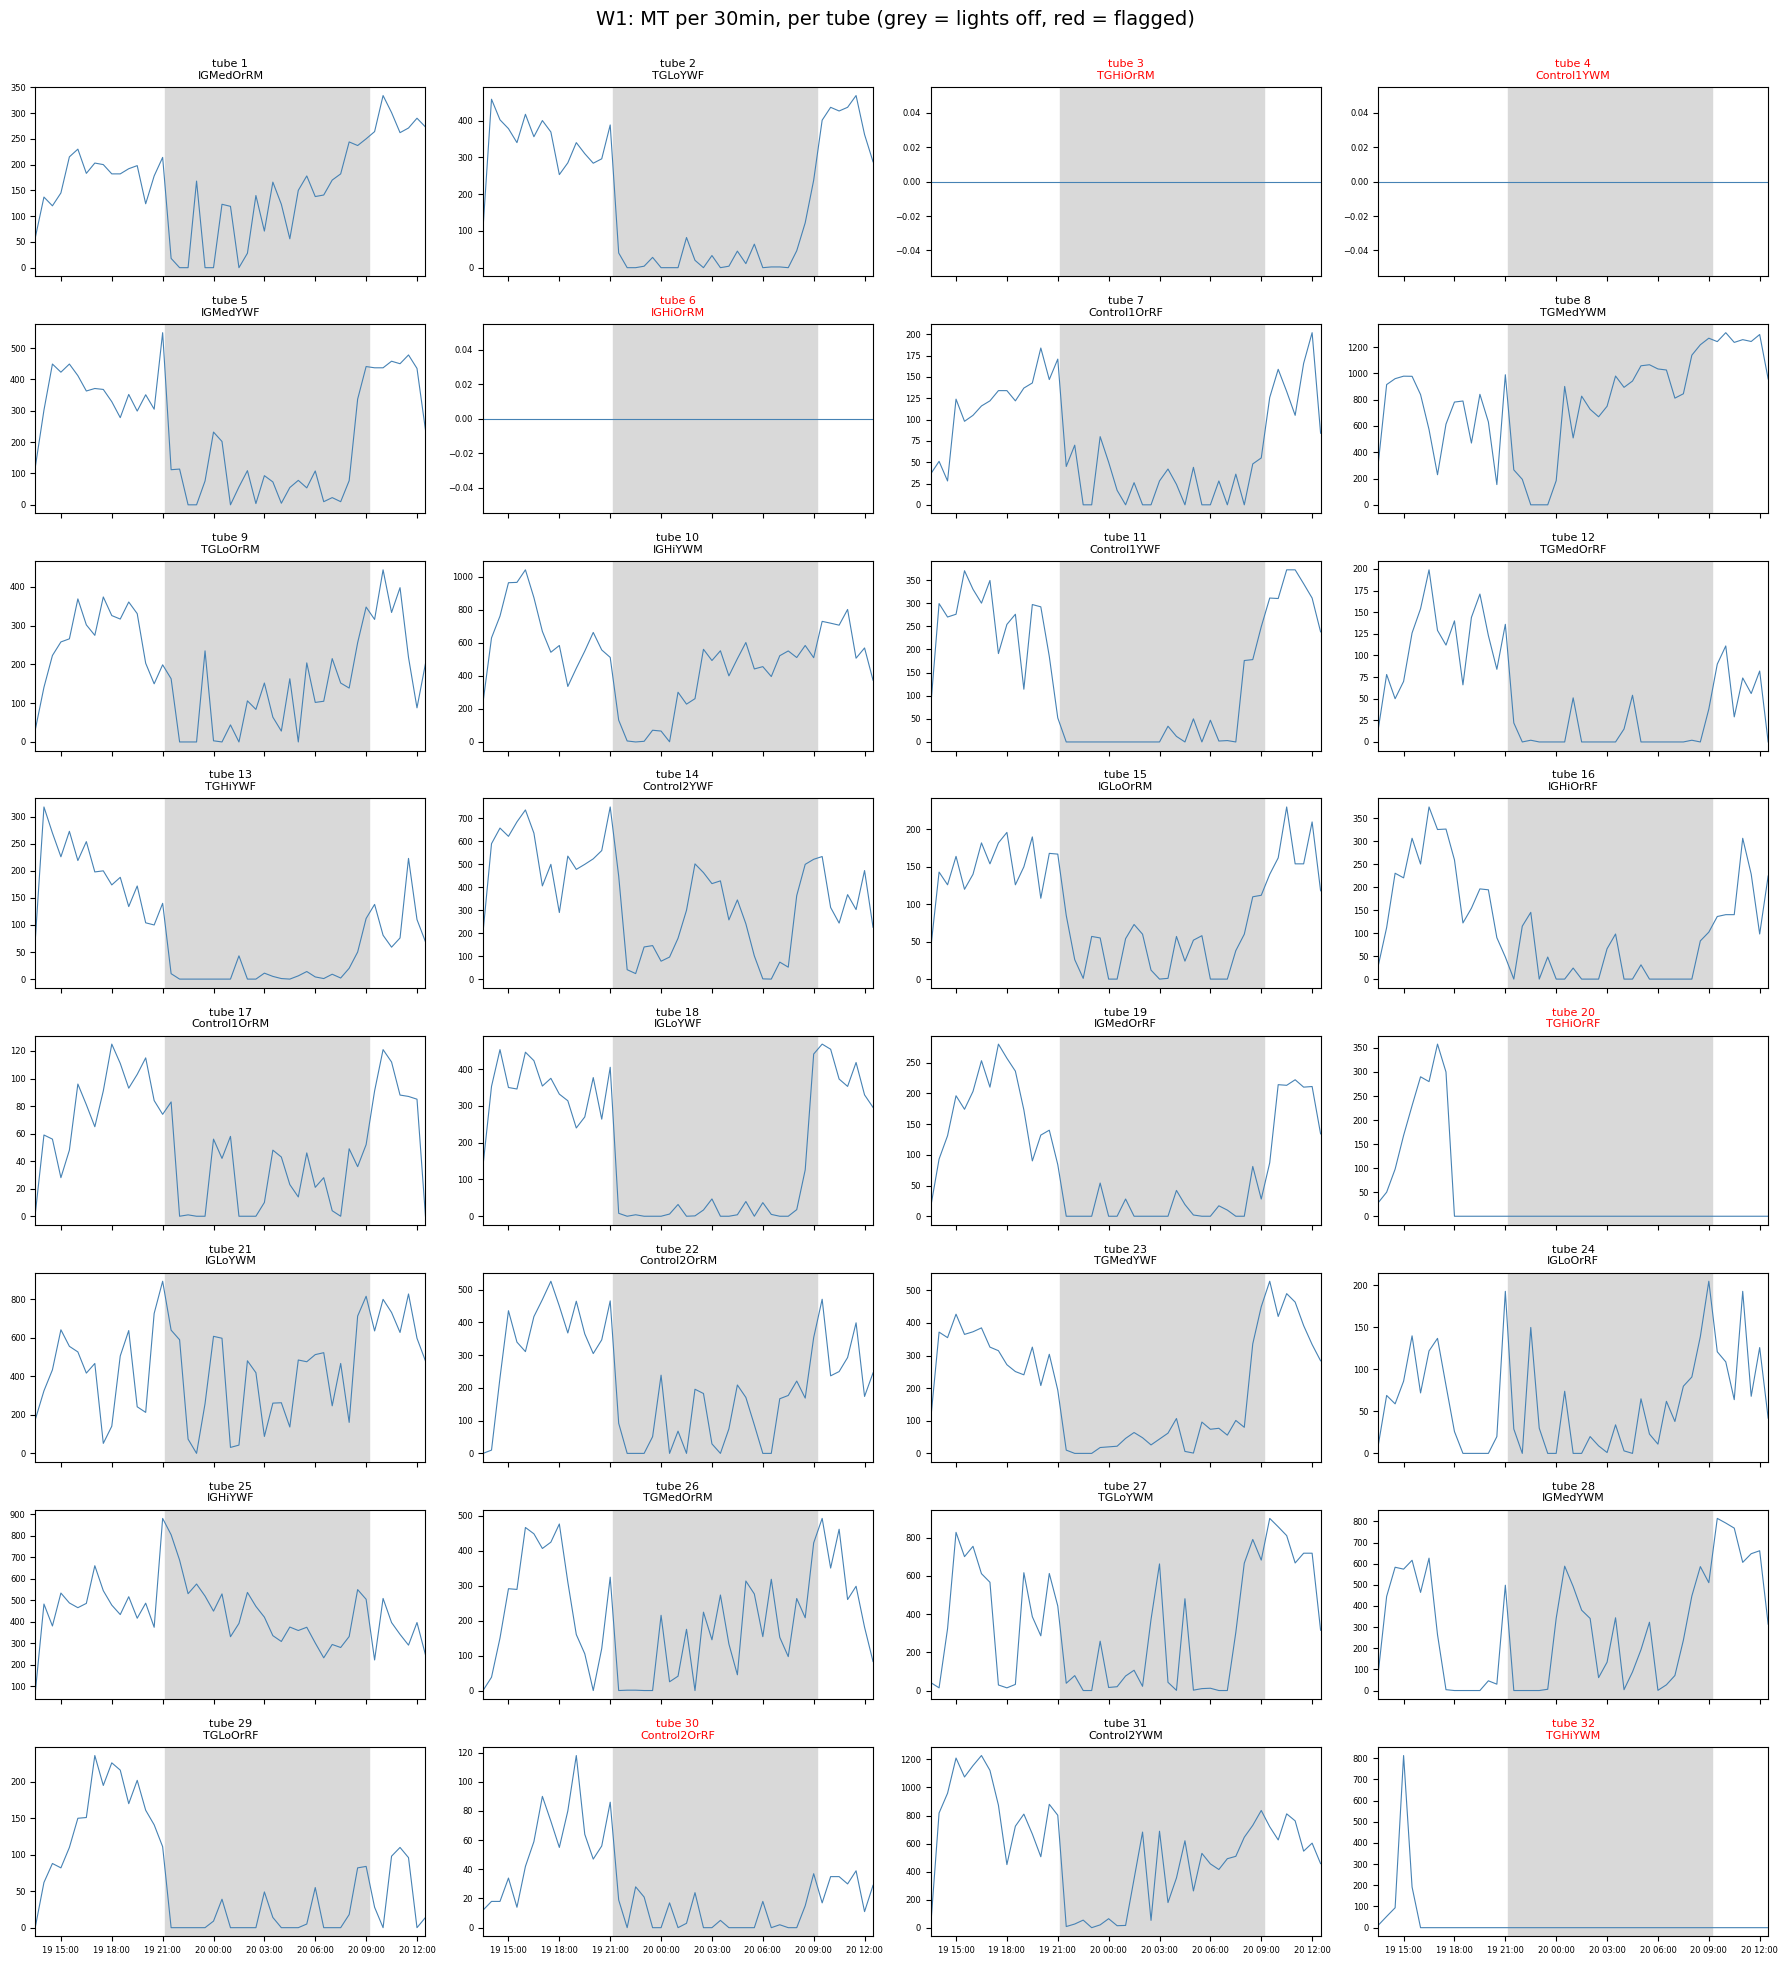

In [15]:
W = 'W1'
b, lay, used = get_window(W)

fig, axes = plt.subplots(8, 4, figsize=(18, 20), sharex=True)
for ax, t in zip(axes.flat, range(1, 33)):
    shade_dark(ax)
    ax.plot(b.index, b[t], lw=0.8, color='steelblue')
    ax.set_title(f'tube {t}\n{lay.loc[t, "label"]}', fontsize=8, color='red' if flagged(W, t) else 'black')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
    ax.tick_params(labelsize=6)
fig.suptitle(f'{W}: {DATA_TYPE} per {BIN}, per tube (grey = lights off, red = flagged)', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(f'{W}_A_all_tubes.png', dpi=130)
plt.show()

2026-09-20 13:06 to 2026-09-21 13:06

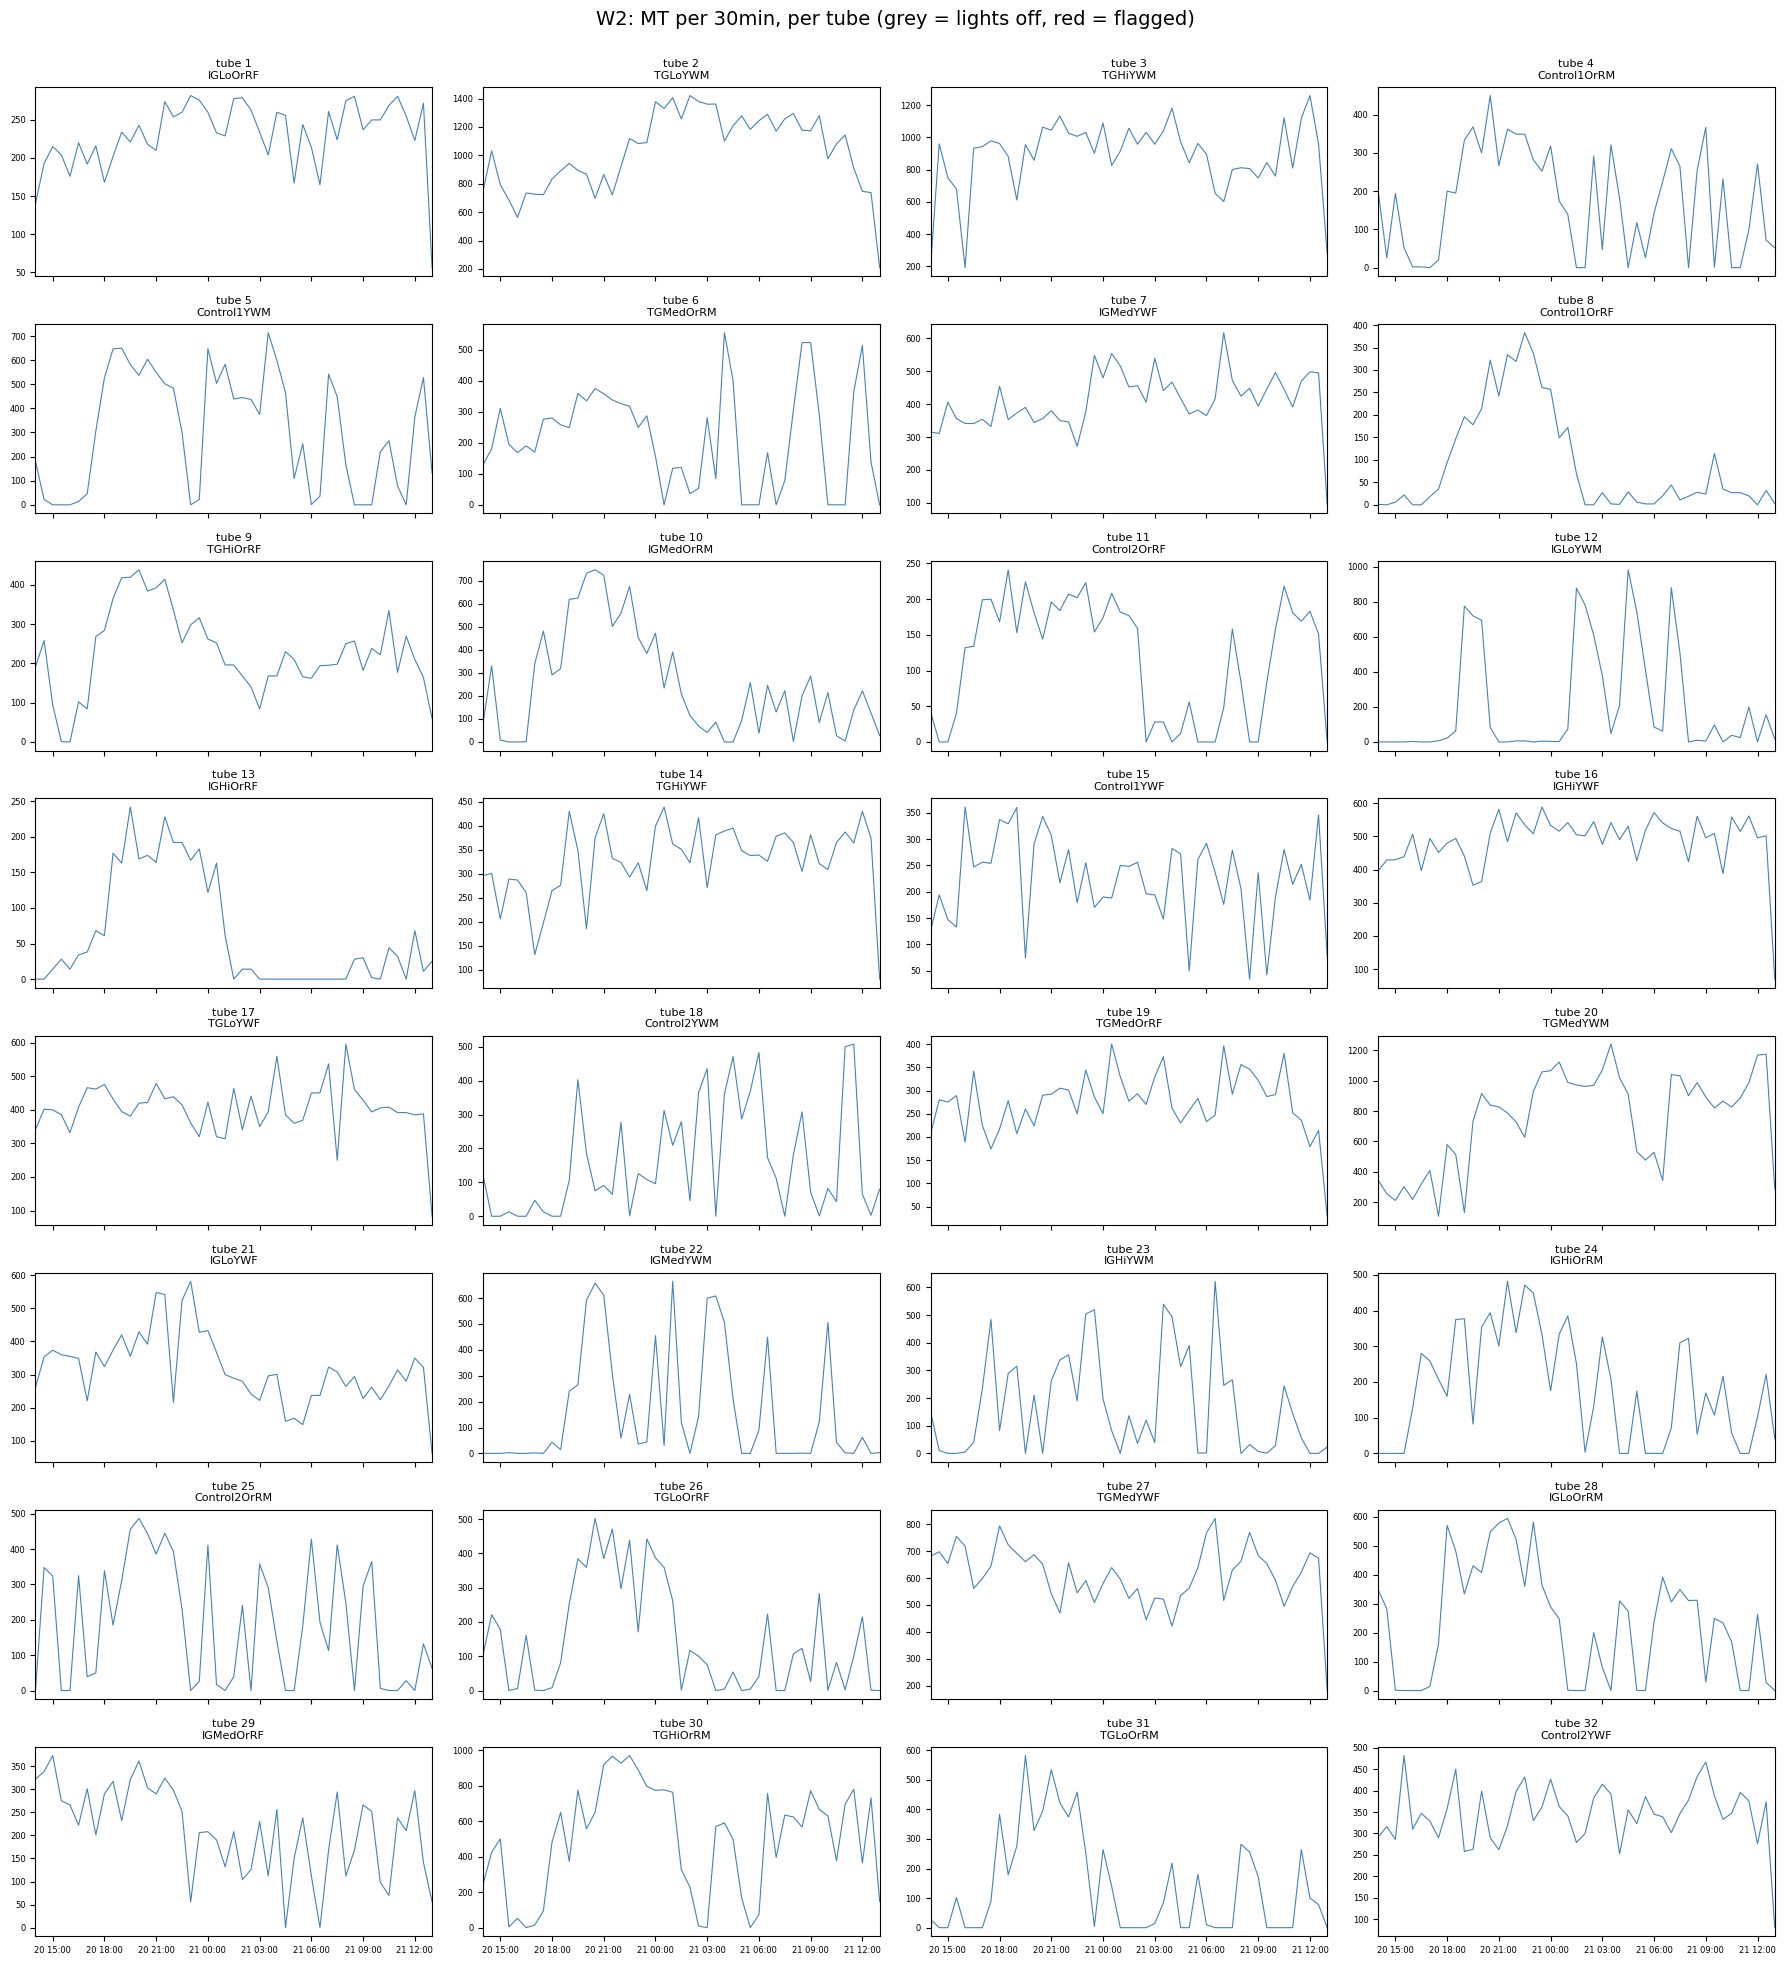

In [16]:
W = 'W2'
b, lay, used = get_window(W)

fig, axes = plt.subplots(8, 4, figsize=(18, 20), sharex=True)
for ax, t in zip(axes.flat, range(1, 33)):
    shade_dark(ax)
    ax.plot(b.index, b[t], lw=0.8, color='steelblue')
    ax.set_title(f'tube {t}\n{lay.loc[t, "label"]}', fontsize=8, color='red' if flagged(W, t) else 'black')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
    ax.tick_params(labelsize=6)
fig.suptitle(f'{W}: {DATA_TYPE} per {BIN}, per tube (grey = lights off, red = flagged)', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(f'{W}_A_all_tubes.png', dpi=130)
plt.show()

2026-09-21 13:19 to 2026-09-22 13:19

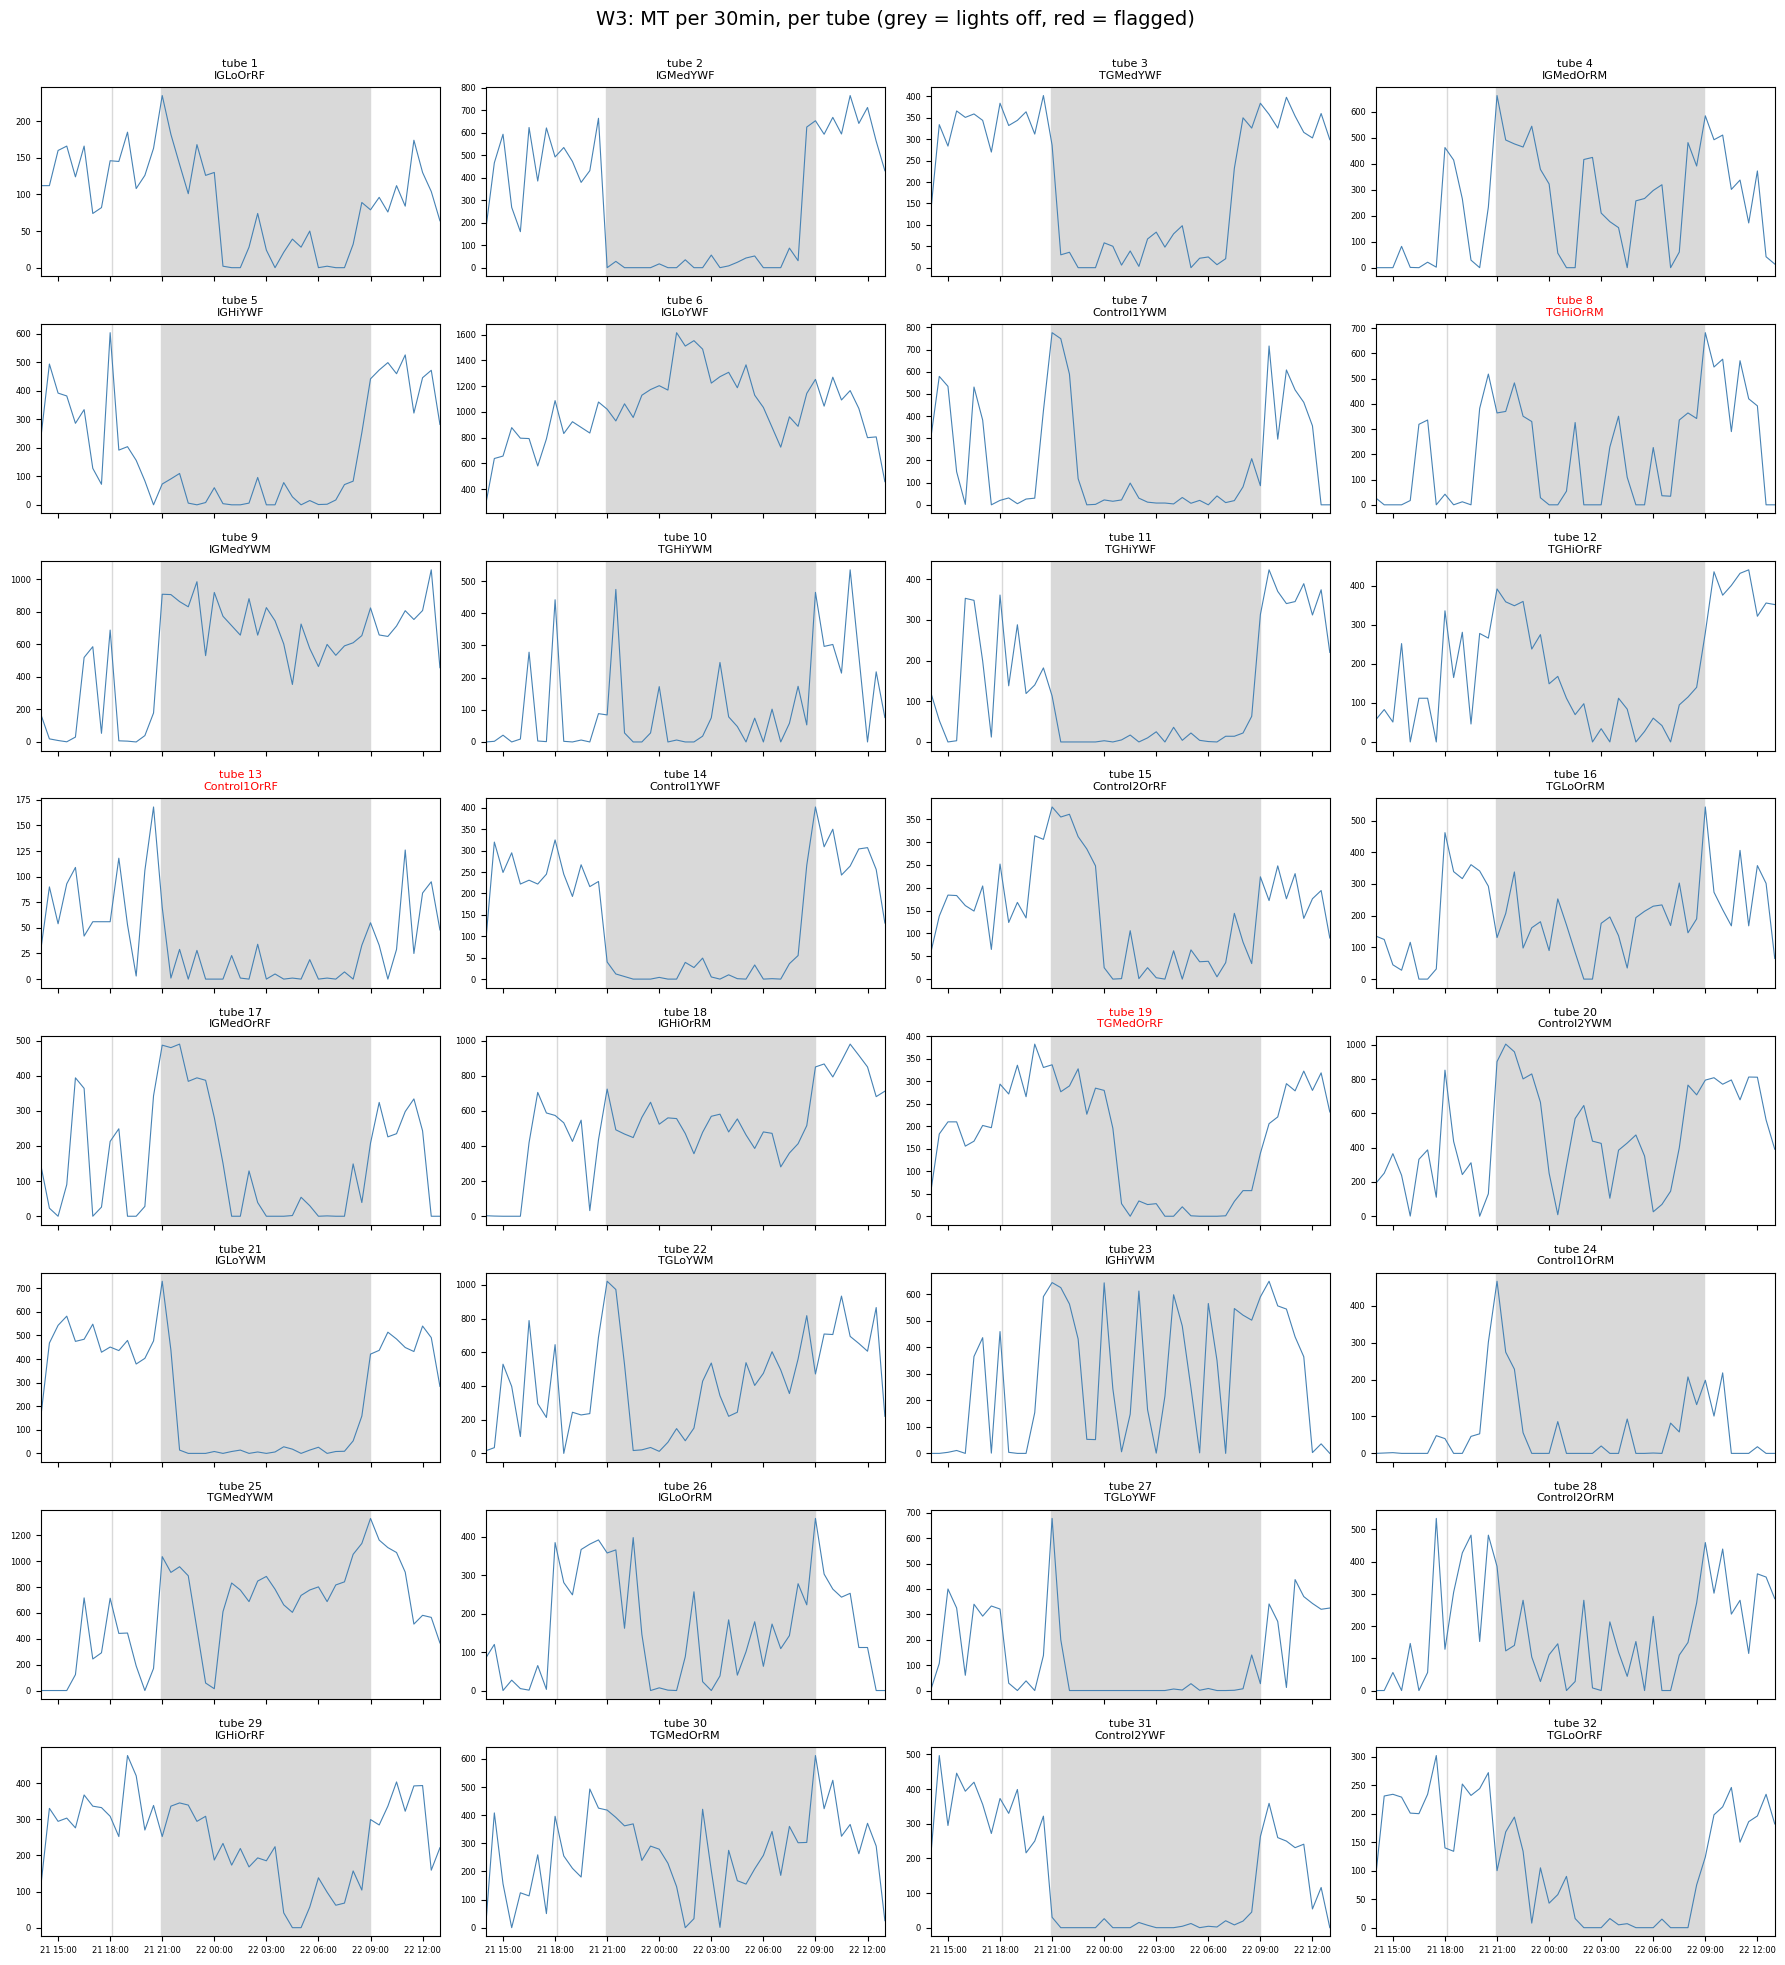

In [17]:
W = 'W3'
b, lay, used = get_window(W)

fig, axes = plt.subplots(8, 4, figsize=(18, 20), sharex=True)
for ax, t in zip(axes.flat, range(1, 33)):
    shade_dark(ax)
    ax.plot(b.index, b[t], lw=0.8, color='steelblue')
    ax.set_title(f'tube {t}\n{lay.loc[t, "label"]}', fontsize=8, color='red' if flagged(W, t) else 'black')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
    ax.tick_params(labelsize=6)
fig.suptitle(f'{W}: {DATA_TYPE} per {BIN}, per tube (grey = lights off, red = flagged)', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(f'{W}_A_all_tubes.png', dpi=130)
plt.show()

#### Figure B: heatmap, tubes sorted by group.
2026-09-19 12:50 to 2026-09-20 12:50

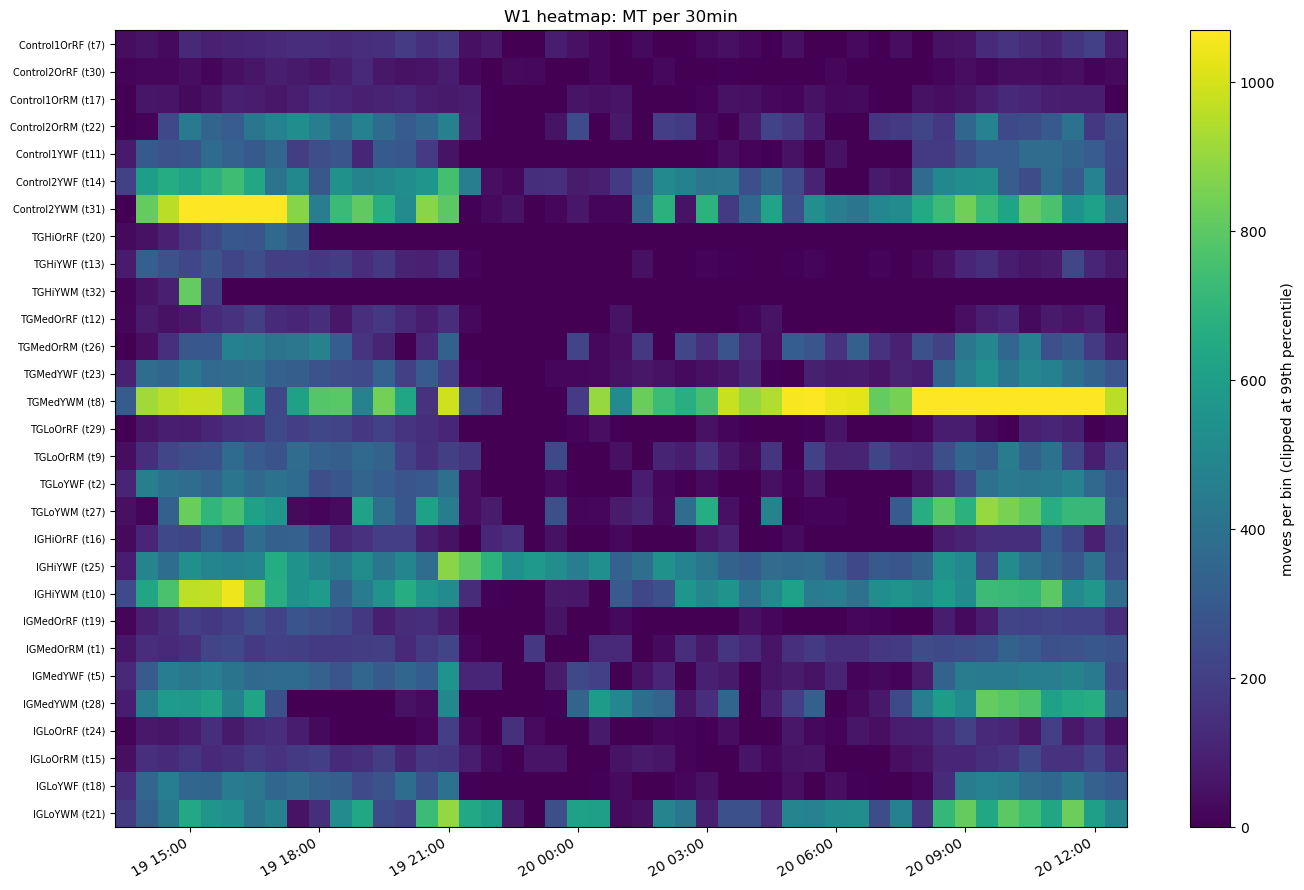

In [18]:
W = 'W1'
b, lay, used = get_window(W)

srt = lay.loc[used].assign(o=lambda x: x['trt_plot'].map(ORDER.index)).sort_values(['o', 'strain', 'sex']).index
fig, ax = plt.subplots(figsize=(14, 9))
im = ax.pcolormesh(mdates.date2num(b.index), np.arange(len(srt)), b[srt].T.values,
                   cmap='viridis', shading='nearest',
                   vmax=np.nanpercentile(b[srt].values, 99))
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
ax.set_yticks(range(len(srt)))
ax.set_yticklabels([f'{lay.loc[t, "label"]} (t{t})' for t in srt], fontsize=7)
ax.invert_yaxis()
ax.set_title(f'{W} heatmap: {DATA_TYPE} per {BIN}')
fig.colorbar(im, label='moves per bin (clipped at 99th percentile)')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(f'{W}_B_heatmap.png', dpi=150)
plt.show()

2026-09-20 13:06 to 2026-09-21 13:06

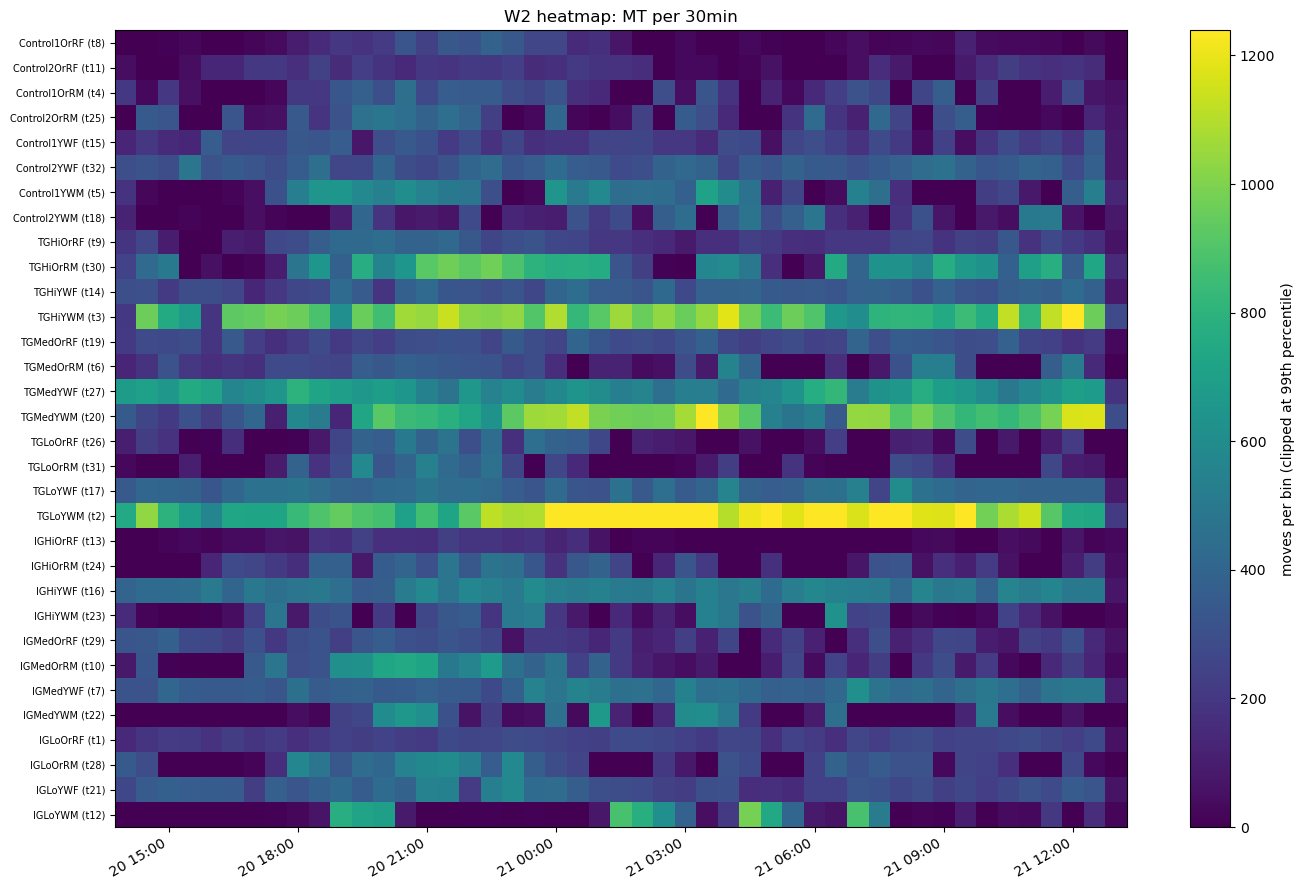

In [19]:
W = 'W2'
b, lay, used = get_window(W)

srt = lay.loc[used].assign(o=lambda x: x['trt_plot'].map(ORDER.index)).sort_values(['o', 'strain', 'sex']).index
fig, ax = plt.subplots(figsize=(14, 9))
im = ax.pcolormesh(mdates.date2num(b.index), np.arange(len(srt)), b[srt].T.values,
                   cmap='viridis', shading='nearest',
                   vmax=np.nanpercentile(b[srt].values, 99))
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
ax.set_yticks(range(len(srt)))
ax.set_yticklabels([f'{lay.loc[t, "label"]} (t{t})' for t in srt], fontsize=7)
ax.invert_yaxis()
ax.set_title(f'{W} heatmap: {DATA_TYPE} per {BIN}')
fig.colorbar(im, label='moves per bin (clipped at 99th percentile)')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(f'{W}_B_heatmap.png', dpi=150)
plt.show()

2026-09-21 13:19 to 2026-09-22 13:19

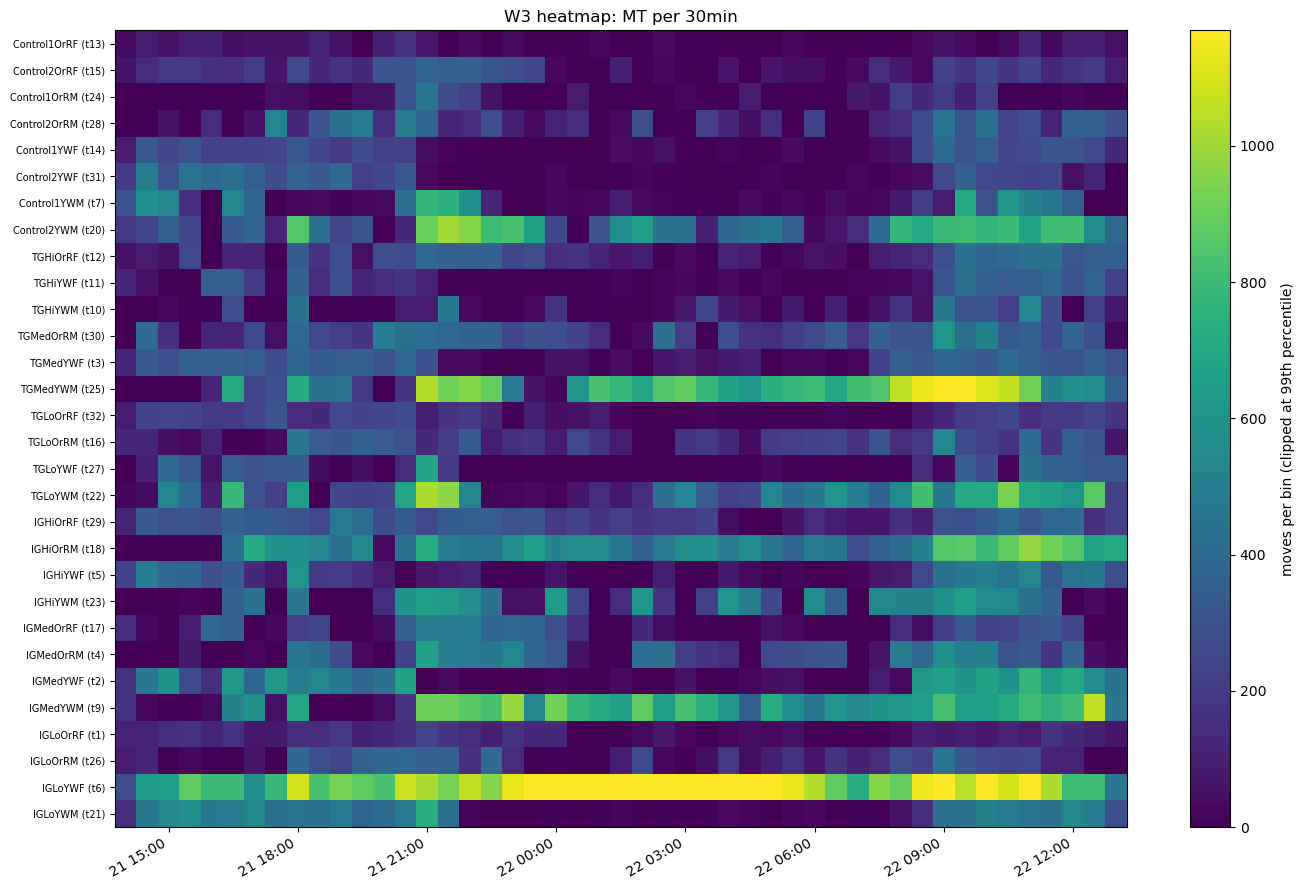

In [20]:
W = 'W3'
b, lay, used = get_window(W)

srt = lay.loc[used].assign(o=lambda x: x['trt_plot'].map(ORDER.index)).sort_values(['o', 'strain', 'sex']).index
fig, ax = plt.subplots(figsize=(14, 9))
im = ax.pcolormesh(mdates.date2num(b.index), np.arange(len(srt)), b[srt].T.values,
                   cmap='viridis', shading='nearest',
                   vmax=np.nanpercentile(b[srt].values, 99))
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
ax.set_yticks(range(len(srt)))
ax.set_yticklabels([f'{lay.loc[t, "label"]} (t{t})' for t in srt], fontsize=7)
ax.invert_yaxis()
ax.set_title(f'{W} heatmap: {DATA_TYPE} per {BIN}')
fig.colorbar(im, label='moves per bin (clipped at 99th percentile)')
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(f'{W}_B_heatmap.png', dpi=150)
plt.show()

#### Figure C: group time courses. This has one panel per strain and sex, with one line per treatment.
2026-09-19 12:50 to 2026-09-20 12:50

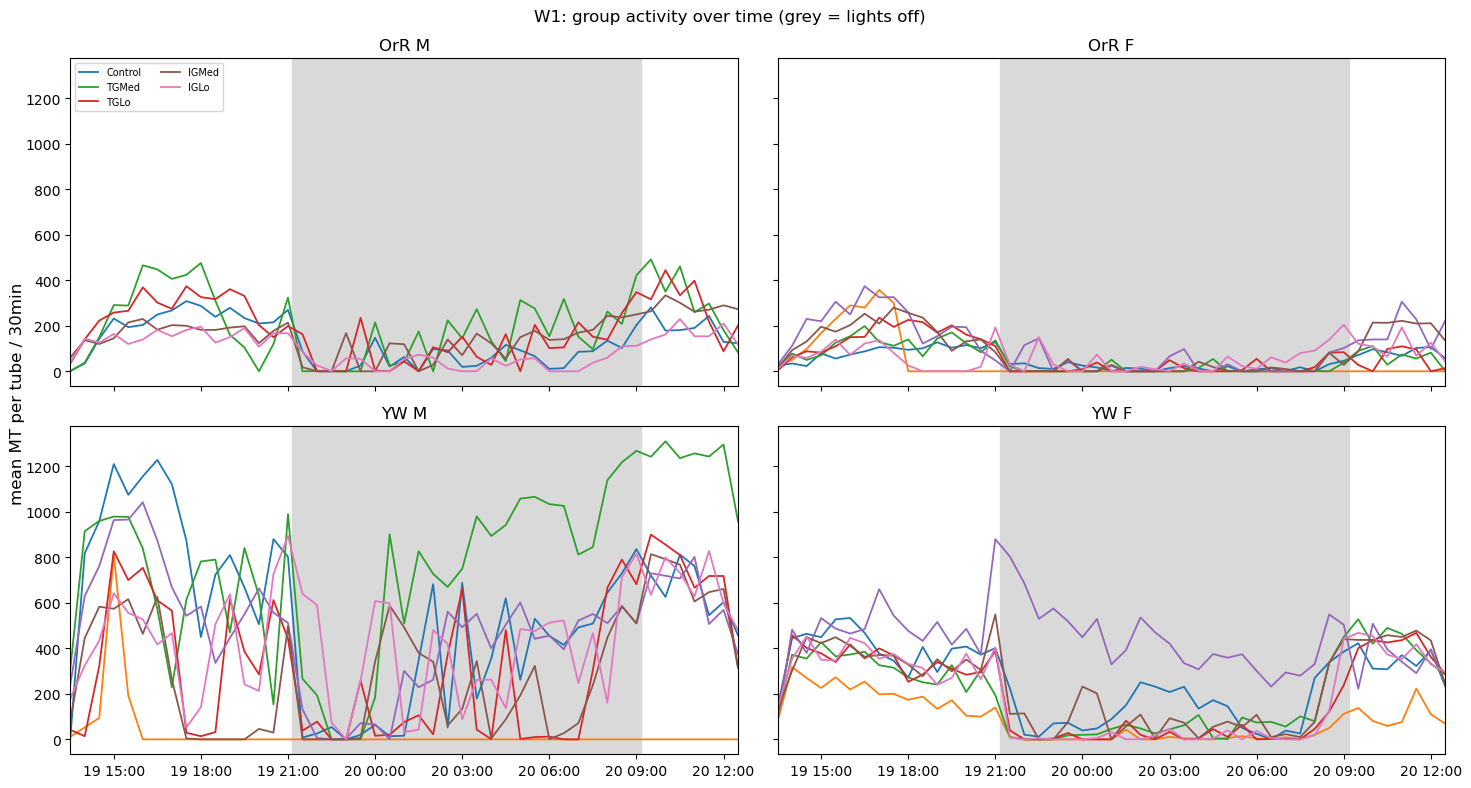

In [21]:
W = 'W1'
b, lay, used = get_window(W)

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, (strain, sex) in zip(axes.flat, itertools.product(['OrR', 'YW'], ['M', 'F'])):
    shade_dark(ax)
    for t in ORDER:
        tubes = [x for x in used if lay.loc[x, 'trt_plot'] == t
                 and lay.loc[x, 'strain'] == strain and lay.loc[x, 'sex'] == sex]
        if tubes:
            ax.plot(b.index, b[tubes].mean(axis=1), label=t, color=COLORS[t], lw=1.3)
    ax.set_title(f'{strain} {sex}')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
axes[0, 0].legend(fontsize=7, ncol=2)
fig.supylabel(f'mean {DATA_TYPE} per tube / {BIN}')
fig.suptitle(f'{W}: group activity over time (grey = lights off)')
fig.tight_layout()
fig.savefig(f'{W}_C_group_timecourse.png', dpi=150)
plt.show()

2026-09-20 13:06 to 2026-09-21 13:06

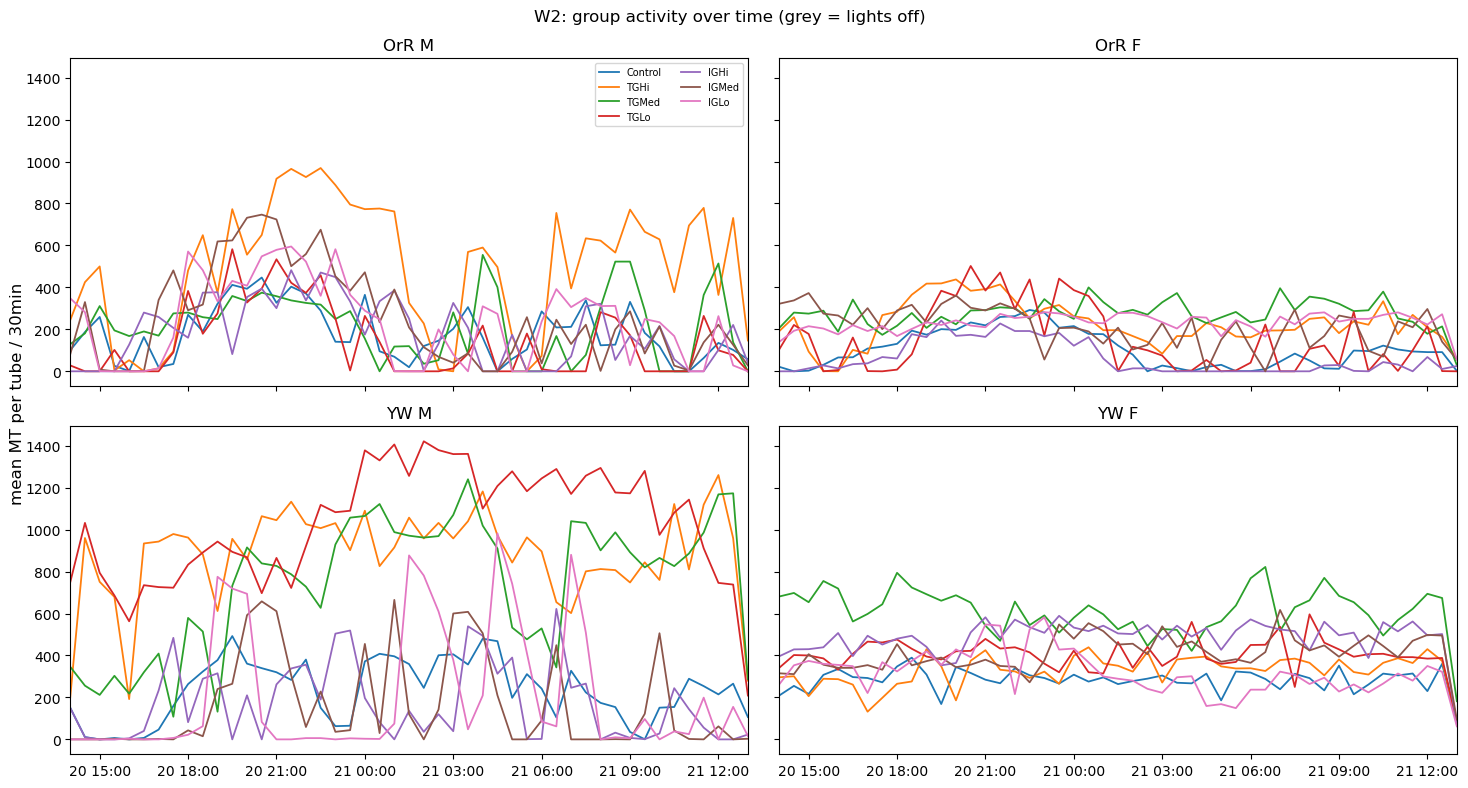

In [22]:
W = 'W2'
b, lay, used = get_window(W)

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, (strain, sex) in zip(axes.flat, itertools.product(['OrR', 'YW'], ['M', 'F'])):
    shade_dark(ax)
    for t in ORDER:
        tubes = [x for x in used if lay.loc[x, 'trt_plot'] == t
                 and lay.loc[x, 'strain'] == strain and lay.loc[x, 'sex'] == sex]
        if tubes:
            ax.plot(b.index, b[tubes].mean(axis=1), label=t, color=COLORS[t], lw=1.3)
    ax.set_title(f'{strain} {sex}')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
axes[0, 0].legend(fontsize=7, ncol=2)
fig.supylabel(f'mean {DATA_TYPE} per tube / {BIN}')
fig.suptitle(f'{W}: group activity over time (grey = lights off)')
fig.tight_layout()
fig.savefig(f'{W}_C_group_timecourse.png', dpi=150)
plt.show()

2026-09-21 13:19 to 2026-09-22 13:19

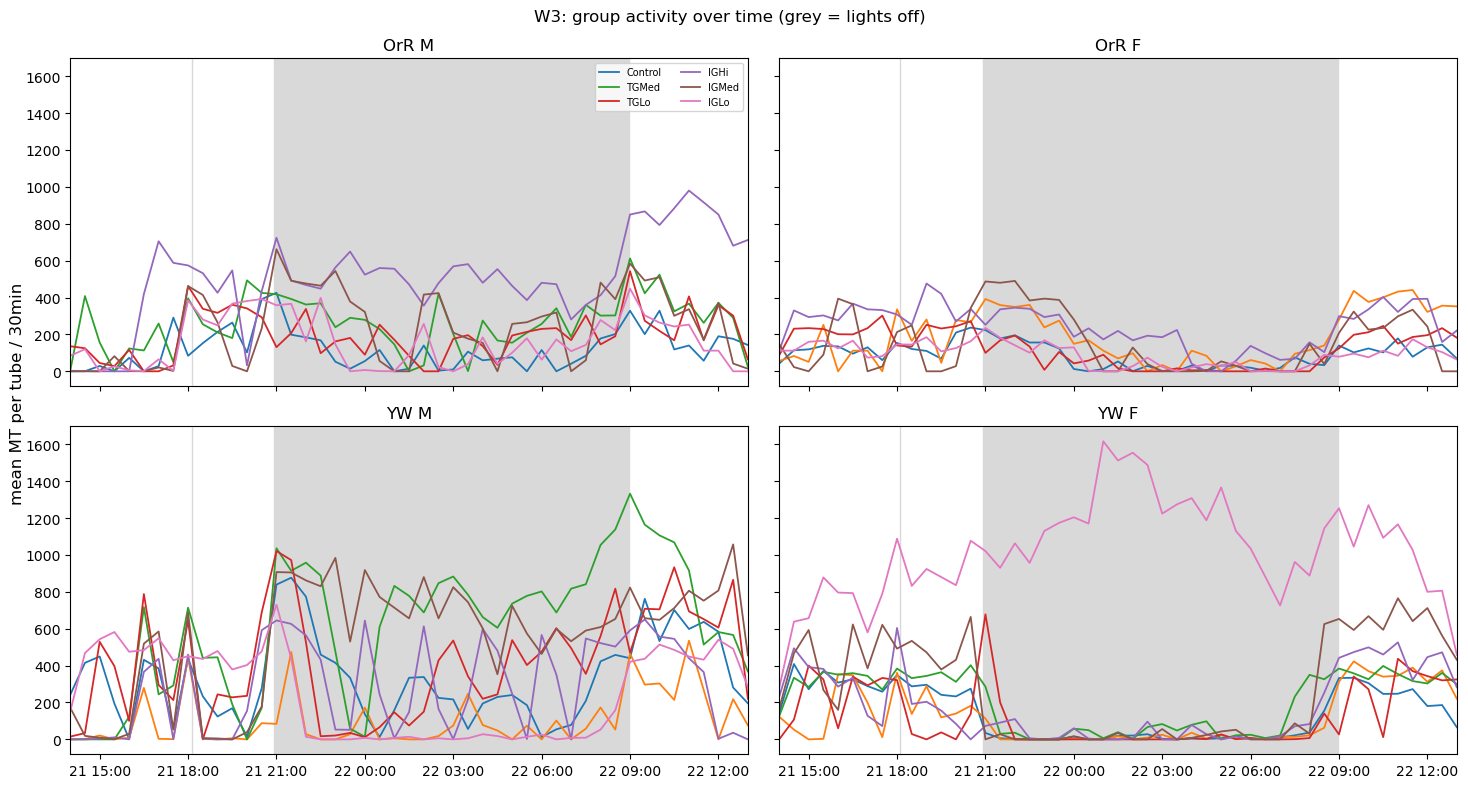

In [23]:
W = 'W3'
b, lay, used = get_window(W)

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, (strain, sex) in zip(axes.flat, itertools.product(['OrR', 'YW'], ['M', 'F'])):
    shade_dark(ax)
    for t in ORDER:
        tubes = [x for x in used if lay.loc[x, 'trt_plot'] == t
                 and lay.loc[x, 'strain'] == strain and lay.loc[x, 'sex'] == sex]
        if tubes:
            ax.plot(b.index, b[tubes].mean(axis=1), label=t, color=COLORS[t], lw=1.3)
    ax.set_title(f'{strain} {sex}')
    ax.set_xlim(b.index.min(), b.index.max())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %H:%M'))
axes[0, 0].legend(fontsize=7, ncol=2)
fig.supylabel(f'mean {DATA_TYPE} per tube / {BIN}')
fig.suptitle(f'{W}: group activity over time (grey = lights off)')
fig.tight_layout()
fig.savefig(f'{W}_C_group_timecourse.png', dpi=150)
plt.show()

In [24]:
ok = summary[~summary['excluded']].copy()
ok['trt_plot'] = (ok['treatment'].str.replace(r'^Control\d$', 'Control', regex=True)
                  if POOL_CONTROLS else ok['treatment'])

def group_plot(metric, ylabel, fname):
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharey=True)
    rng = np.random.default_rng(0)
    wcolors = {n: c for n, c in zip(WINDOWS, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])}
    for ax, (strain, sex) in zip(axes, itertools.product(['OrR', 'YW'], ['M', 'F'])):
        sub = ok[(ok.strain == strain) & (ok.sex == sex)]
        st = sub.groupby('trt_plot')[metric].agg(['mean', 'sem']).reindex(ORDER)
        ax.bar(range(len(ORDER)), st['mean'], yerr=st['sem'], color='0.8', capsize=3, zorder=1)
        for n, c in wcolors.items():
            ss = sub[sub.window == n]
            ax.scatter([ORDER.index(t) + rng.uniform(-.15, .15) for t in ss['trt_plot']],
                       ss[metric], color=c, s=28, zorder=3, label=n)
        ax.set_xticks(range(len(ORDER)))
        ax.set_xticklabels(ORDER, rotation=45, ha='right')
        ax.set_title(f'{strain} {sex}')
    axes[0].set_ylabel(ylabel)
    axes[0].legend(title='run', fontsize=8)
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()

#### Figure D: total activity per group across all runs.

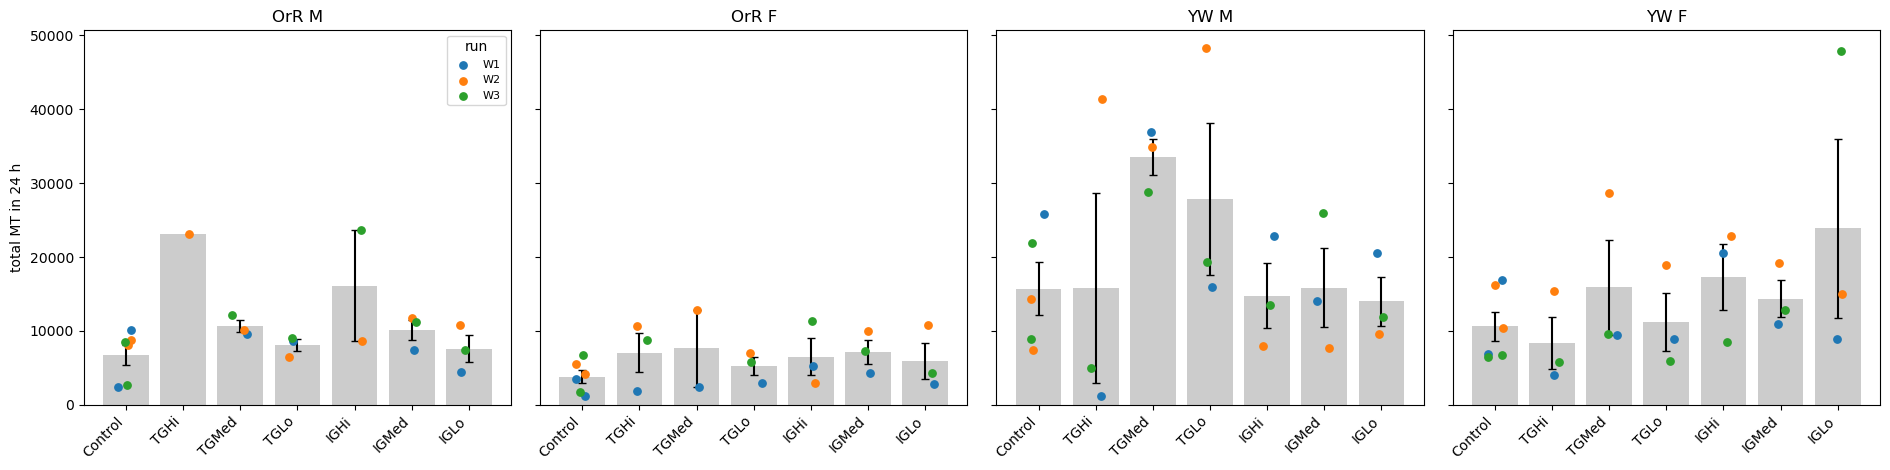

In [25]:
group_plot('total_moves', f'total {DATA_TYPE} in 24 h', 'D_group_total_moves.png')

#### Figure E: sleep per group across all runs.

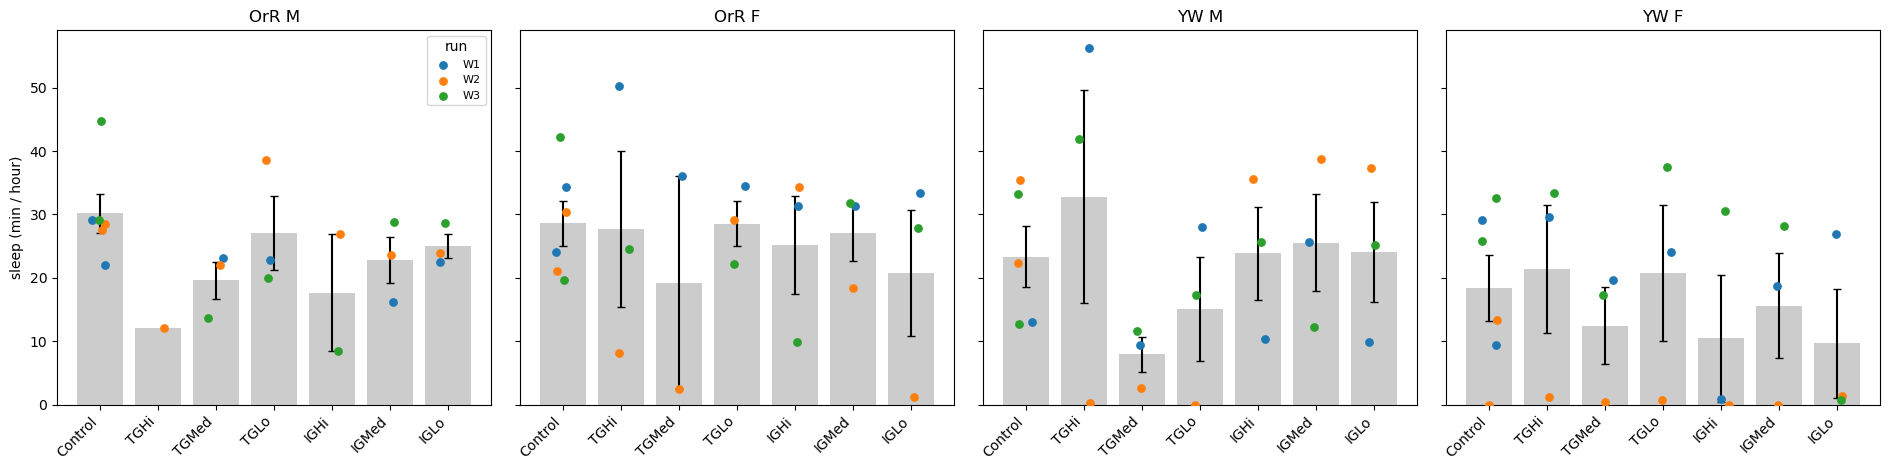

In [26]:
group_plot('sleep_min_per_h', 'sleep (min / hour)', 'E_group_sleep.png')

In [27]:
by_group = (ok.groupby(['trt_plot', 'strain', 'sex'])[['total_moves', 'sleep_min_per_h']]
              .agg(['count', 'mean', 'sem']).round(1))
display(by_group)
summary.round(2).to_csv('per_tube_summary.csv', index=False)
by_group.to_csv('per_group_summary.csv')

total_moves                   sleep_min_per_h            
                          count     mean      sem           count  mean   sem
trt_plot strain sex                                                          
Control  OrR    F             6   3807.5    857.4               6  28.6   3.6
                M             6   6767.7   1351.7               6  30.2   3.1
         YW     F             6  10604.5   1961.3               6  18.4   5.2
                M             5  15689.8   3580.7               5  23.4   4.8
IGHi     OrR    F             3   6514.7   2532.9               3  25.2   7.7
                M             2  16142.5   7496.5               2  17.6   9.2
         YW     F             3  17294.3   4452.7               3  10.5  10.0
                M             3  14783.3   4352.3               3  23.9   7.3
IGLo     OrR    F             3   5959.7   2465.4               3  20.8   9.9
                M             3   7584.7   1850.8               3  25.0   1.9
         YW     F             3  23926.7  12117.5               3   9.7   8.6
                M             3  14011.0   3338.9               3  24.1   7.9
IGMed    OrR    F             3   7154.7   1659.3               3  27.2   4.4
                M             3  10147.0   1355.6               3  22.8   3.6
         YW     F             3  14351.7   2512.5               3  15.6   8.3
                M             3  15875.3   5333.4               3  25.6   7.7
TGHi     OrR    F             3   7060.7   2689.0               3  27.7  12.3
                M             1  23180.0      NaN               1  12.1   NaN
         YW     F             3   8395.3   3503.5               3  21.4  10.1
                M             3  15845.3  12836.9               3  32.8  16.8
TGLo     OrR    F             3   5262.3   1187.6               3  28.6   3.6
                M             3   8065.7    805.0               3  27.1   5.8
         YW     F             3  11251.7   3929.9               3  20.8  10.8
                M             3  27827.3  10274.7               3  15.1   8.1
TGMed    OrR    F             2   7635.0   5213.0               2  19.3  16.7
                M             3  10627.7    801.6               3  19.6   3.0
         YW     F             3  15909.7   6406.7               3  12.5   6.0
                M             3  33548.3   2423.3               3   7.9   2.7